In [ ]:
import os
import random
import sys
import time

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import torch
# from datasets import getPairedDataset
from model import DecoderA, DecoderB, EncoderA, EncoderB
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.datasets import MNIST, SVHN
from util import apply_poe, unpack_data

sys.path.append("../")
import pickle

import probtorch

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
class ViewDataset(Dataset):
    def __init__(self, v1, v2):
        self.v1 = torch.tensor(v1).float()
        self.v2 = torch.tensor(v2).float()
        self.data_len = v1.shape[0]

    def __getitem__(self, index):
        return self.v1[index], self.v2[index], index

    def __len__(self):
        return self.data_len

test_data = np.load("../../data/sprites/single-pose_private-angle_test.npz")

A_test = torch.Tensor(test_data["view1"].reshape(-1, 64 * 64 * 3)).to(device)
B_test = torch.Tensor(test_data["view2"].reshape(-1, 64 * 64 * 3)).to(device)

In [4]:
n_shared = 500
n_privateA = 2
n_privateB = 2
wseed = 0

encA = EncoderA(wseed, zShared_dim=n_shared, zPrivate_dim=n_privateA).to(device)
decA = DecoderA(wseed, zShared_dim=n_shared, zPrivate_dim=n_privateA).to(device)
encB = EncoderB(wseed, zShared_dim=n_shared, zPrivate_dim=n_privateB).to(device)
decB = DecoderB(wseed, zShared_dim=n_shared, zPrivate_dim=n_privateB).to(device)

decA.load_state_dict(torch.load("../weights/sprites/sprites_private-angle-decA.rar"))
encA.load_state_dict(torch.load("../weights/sprites/sprites_private-angle-encA.rar"))
encB.load_state_dict(torch.load("../weights/sprites/sprites_private-angle-encB.rar"))
decB.load_state_dict(torch.load("../weights/sprites/sprites_private-angle-decB.rar"))

q = encA(A_test, num_samples=1) 
q = encB(B_test, num_samples=1, q=q)    

mu_poe, std_poe = apply_poe(
                True,
                q["sharedA"].dist.loc,
                q["sharedA"].dist.scale,
                q["sharedB"].dist.loc,
                q["sharedB"].dist.scale,
            )
q.normal(mu_poe, std_poe, name="poe")


a_hat = decA.forward2(torch.cat((q["privateA"].dist.loc , q["poe"].dist.loc), dim=-1)).squeeze(0).detach()
b_hat = decB.forward2(torch.cat((q["privateB"].dist.loc , q["poe"].dist.loc), dim=-1)).squeeze(0).detach()

z_a = q["privateA"].dist.loc.squeeze(0).detach().cpu().numpy()
z_b = q["privateB"].dist.loc.squeeze(0).detach().cpu().numpy()
z_a_shared = q["sharedA"].dist.loc.squeeze(0).detach().cpu().numpy()
z_b_shared = q["sharedB"].dist.loc.squeeze(0).detach().cpu().numpy()
z_shared = q["poe"].dist.loc.squeeze(0).detach().cpu().numpy()


In [4]:
mse = torch.nn.functional.mse_loss(a_hat, A_test, reduction='none').mean(dim=0).cpu().detach().numpy()
nonzero = np.argwhere(A_test.var(dim=0).cpu().detach().numpy() > 0).flatten()

vars_unexp_raw = mse[nonzero]/A_test.var(dim=0).cpu().detach().numpy()[nonzero]

vars_exp = ((A_test.var(dim=0).cpu().detach().numpy()[nonzero] * (1 - vars_unexp_raw))).sum()/ A_test.var(dim=0).cpu().detach().numpy()[nonzero].sum()
vars_exp

0.88508564

In [5]:
mse = torch.nn.functional.mse_loss(b_hat, B_test, reduction='none').mean(dim=0).cpu().detach().numpy()
nonzero = np.argwhere(B_test.var(dim=0).cpu().detach().numpy() > 0).flatten()

vars_unexp_raw = mse[nonzero]/B_test.var(dim=0).cpu().detach().numpy()[nonzero]

vars_exp = ((B_test.var(dim=0).cpu().detach().numpy()[nonzero] * (1 - vars_unexp_raw))).sum()/ B_test.var(dim=0).cpu().detach().numpy()[nonzero].sum()
vars_exp

0.8822241

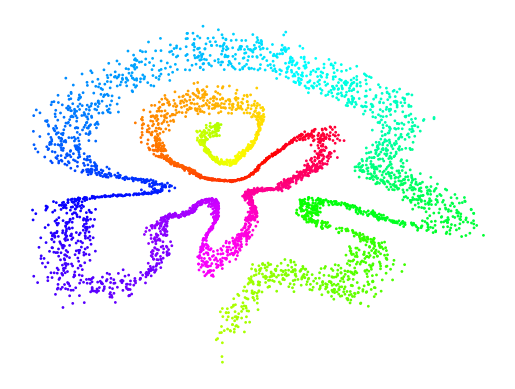

In [6]:
plt.scatter(z_a[:, 0], z_a[:, 1], c=test_data["angles"][:,0], cmap="hsv", s=1)
plt.axis("off")
plt.savefig("../../figures/dmvae_sprites_private_angle_z_a.png", dpi=300, bbox_inches="tight")

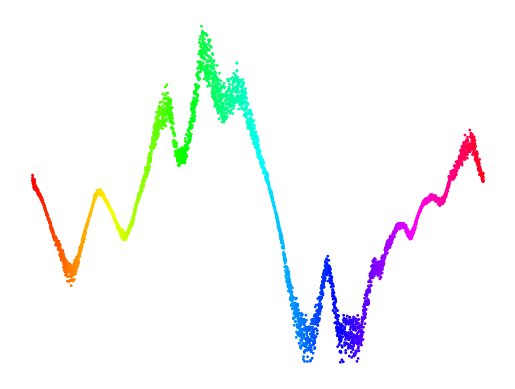

In [7]:
plt.scatter(test_data["angles"][:,0], z_a[:,0], c=test_data["angles"][:,0], cmap="hsv", s=1)
plt.axis("off")
plt.savefig("../../figures/dmvae_sprites_private_angle_za0_vs_theta.png", dpi=300, bbox_inches="tight")

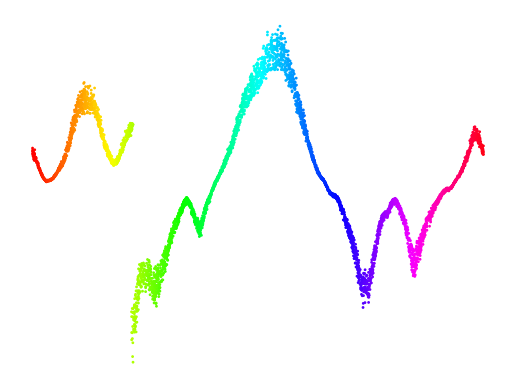

In [8]:
plt.scatter(test_data["angles"][:,0], z_a[:,1], c=test_data["angles"][:,0], cmap="hsv", s=1)
plt.axis("off")
plt.savefig("../../figures/dmvae_sprites_private_angle_za1_vs_theta.png", dpi=300, bbox_inches="tight")

In [6]:
# Calculate variance explained by angle
angle_inds = np.argsort(test_data["angles"][:,0])
window_width = 28 # 0.5 degrees
var_1 = np.var(z_a[:,0])
var_2 = np.var(z_a[:,1])

window_vars_1 = []
window_vars_2 = []

for i in range(angle_inds.shape[0] - window_width):
    window_vars_1.append(np.var(z_a[angle_inds[i:i+window_width], 0]))
    window_vars_2.append(np.var(z_a[angle_inds[i:i+window_width], 1]))

window_vars_1 = np.array(window_vars_1)
window_vars_2 = np.array(window_vars_2)

avg_var_1 = np.mean(window_vars_1)/var_1
avg_var_2 = np.mean(window_vars_2)/var_2

std_1 = np.std(z_a[:,0])
std_2 = np.std(z_a[:,1])
print((var_1 * (1-avg_var_1) + var_2 * (1-avg_var_2))/(var_1 + var_2))
print((std_1 * (1-np.sqrt(avg_var_1)) + std_2 * (1-np.sqrt(avg_var_2)))/(std_1 + std_2))

0.9849996357608588
0.8811209390160535


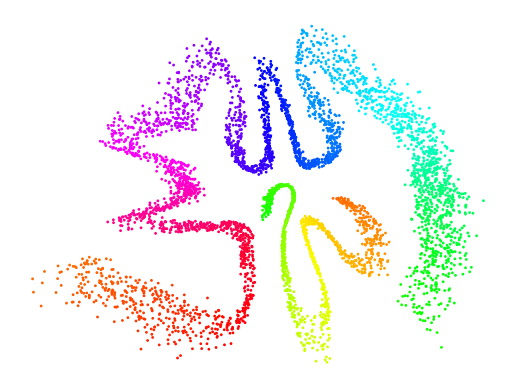

In [121]:
plt.scatter(z_b[:, 0], z_b[:, 1], c=test_data["angles"][:,1], cmap="hsv", s=1)
plt.axis("off")
plt.savefig("../../figures/dmvae_sprites_private_angle_z_b.png", dpi=300, bbox_inches="tight")

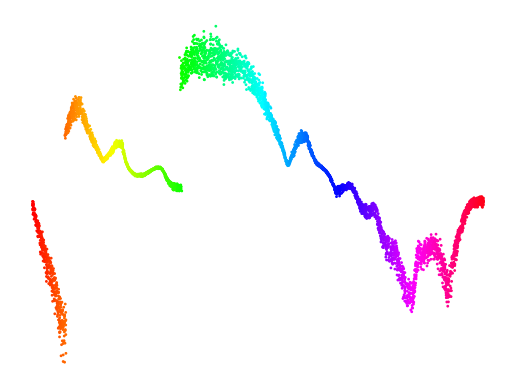

In [122]:
plt.scatter(test_data["angles"][:,1], z_b[:,0], c=test_data["angles"][:,1], cmap="hsv", s=1)
plt.axis("off")
plt.savefig("../../figures/dmvae_sprites_private_angle_zb0_vs_theta.png", dpi=300, bbox_inches="tight")

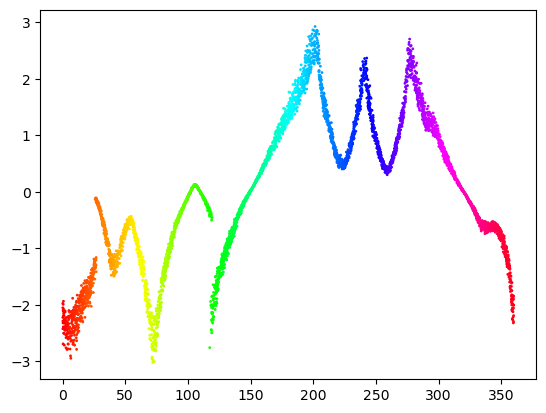

In [123]:
plt.scatter(test_data["angles"][:,1], z_b[:,1], c=test_data["angles"][:,1], cmap="hsv", s=1)
# plt.axis("off")
plt.savefig("../../figures/dmvae_sprites_private_angle_zb1_vs_theta.png", dpi=300, bbox_inches="tight")

In [7]:
# Calculate variance explained by angle
angle_inds = np.argsort(test_data["angles"][:,1])
window_width = 28 # 0.5 degrees
var_1 = np.var(z_b[:,0]*1000)
var_2 = np.var(z_b[:,1]*1000)
asdf = None

window_vars_1 = []
window_vars_2 = []

for i in range(0, angle_inds.shape[0], window_width):
    window_vars_1.append(np.var(z_b[angle_inds[i:i+window_width], 0]*1000))
    window_vars_2.append(np.var(z_b[angle_inds[i:i+window_width], 1]*1000))

window_vars_1 = np.array(window_vars_1)
window_vars_2 = np.array(window_vars_2)

avg_var_1 = np.mean(window_vars_1)/var_1
avg_var_2 = np.mean(window_vars_2)/var_2

std_1 = np.std(z_b[:,0])
std_2 = np.std(z_b[:,1])
print((var_1 * (1-avg_var_1) + var_2 * (1-avg_var_2))/(var_1 + var_2))
print((std_1 * (1-np.sqrt(avg_var_1)) + std_2 * (1-np.sqrt(avg_var_2)))/(std_1 + std_2))

0.9831235948444321
0.8709893038488852


In [5]:
unique, inverse_inds = np.unique(test_data["inds"], return_inverse=True)
unique_inds = {}

for id in unique:
    unique_inds[unique[id]] = np.argwhere(inverse_inds == id).flatten()

In [13]:
tsne = TSNE(n_components=2, perplexity=30, random_state=0)
z_a_shared_tsne = tsne.fit_transform(z_a_shared)

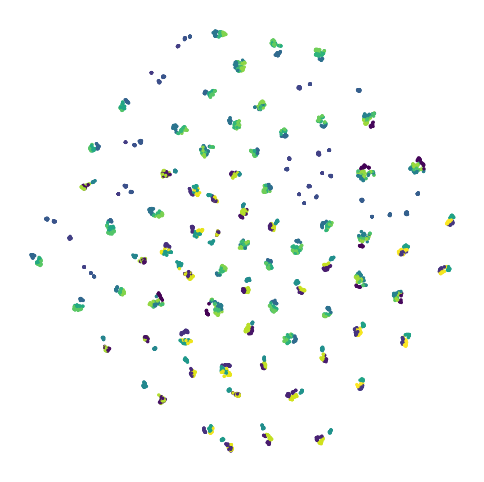

In [129]:
plt.figure(figsize=(6, 6))
test_angles = test_data["angles"]
plt.scatter(z_a_shared_tsne[:, 0], z_a_shared_tsne[:, 1], c=test_data["inds"], s=2)
plt.axis("off")
# plt.colorbar()
plt.savefig("../../figures/dmvae_sprites_private_angle_z_a2b_tsne.png", dpi=300, bbox_inches="tight")

In [130]:
tsne = TSNE(n_components=2, perplexity=30, random_state=0)
z_b_shared_tsne = tsne.fit_transform(z_b_shared)

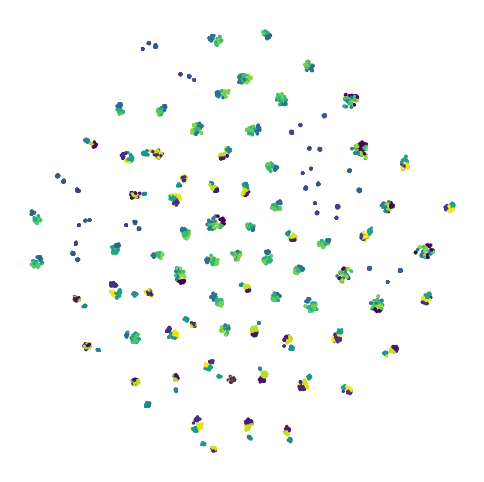

In [131]:
plt.figure(figsize=(6, 6))
test_angles = test_data["angles"]
plt.scatter(z_b_shared_tsne[:, 0], z_b_shared_tsne[:, 1], c=test_data["inds"], s=2)
plt.axis("off")
# plt.colorbar()
plt.savefig("../../figures/dmvae_sprites_private_angle_z_b2a_tsne.png", dpi=300, bbox_inches="tight")

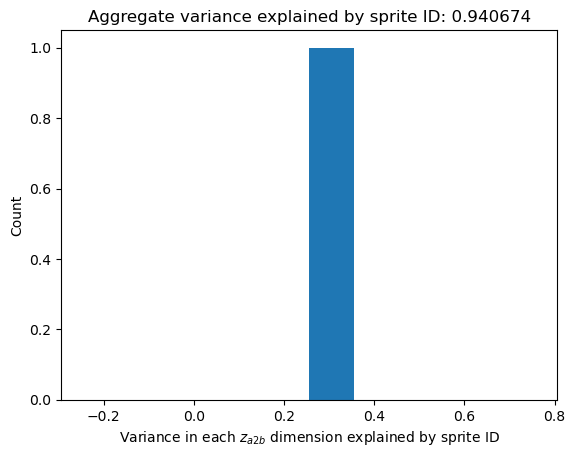

In [6]:
z_a2b = z_a_shared.copy()
unexp_var_sprites = np.zeros((len(unique), 500))

for id in unique:
    unexp_var_sprites[id] = z_a2b[unique_inds[id]].var(axis=0) # variance within sprite, i.e. variance not explained by sprite id

percent_unexp_var_sprites = unexp_var_sprites / z_a2b.var(axis=0) # divide by total variance
percent_exp_var = 1 - np.sqrt(percent_unexp_var_sprites.mean(axis=0)) # for each sprite and dimension, how much variance is explained by sprite id

weighted_exp_var = (z_a2b.var(axis=0) * percent_exp_var).sum()/ z_a2b.var(axis=0).sum() # weight by total variance

# print(percent_exp_var.mean(axis=0))
plt.hist(percent_exp_var.mean(axis=0)); 
plt.xlabel(r"Variance in each $z_{a2b}$ dimension explained by sprite ID")
plt.ylabel("Count")
plt.title("Aggregate variance explained by sprite ID: %.6f" % weighted_exp_var);

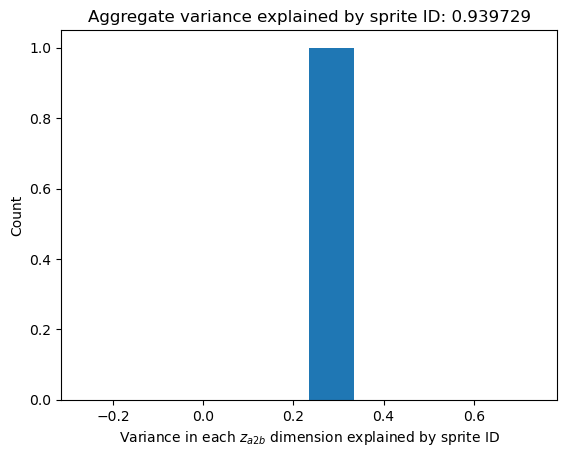

In [10]:
z_b2a = z_b_shared.copy()
unexp_var_sprites = np.zeros((len(unique), 500))

for id in unique:
    unexp_var_sprites[id] = z_b2a[unique_inds[id]].var(axis=0) # variance within sprite, i.e. variance not explained by sprite id

percent_unexp_var_sprites = unexp_var_sprites / z_b2a.var(axis=0) # divide by total variance
percent_exp_var = 1 - np.sqrt(percent_unexp_var_sprites.mean(axis=0)) # for each sprite and dimension, how much variance is explained by sprite id

weighted_exp_var = (z_b2a.var(axis=0) * percent_exp_var).sum()/ z_b2a.var(axis=0).sum() # weight by total variance

plt.hist(percent_exp_var.mean(axis=0)); 
plt.xlabel(r"Variance in each $z_{a2b}$ dimension explained by sprite ID")
plt.ylabel("Count")
plt.title("Aggregate variance explained by sprite ID: %.6f" % weighted_exp_var);

In [134]:
A_test_img = A_test.cpu().detach().numpy().reshape(-1, 64, 64, 3)
B_test_img = B_test.cpu().detach().numpy().reshape(-1, 64, 64, 3)

a_hat_img = a_hat.cpu().detach().numpy().reshape(-1, 64, 64, 3)
b_hat_img = b_hat.cpu().detach().numpy().reshape(-1, 64, 64, 3)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


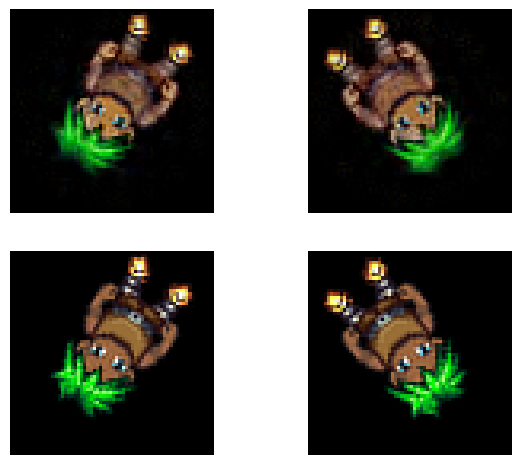

In [136]:
ind = np.random.randint(0, A_test_img.shape[0])

plt.subplot(2, 2, 3)
plt.imshow(A_test_img[ind])
# plt.title("view A")
plt.axis("off")

plt.subplot(2, 2, 1)
plt.imshow(a_hat_img[ind])
# plt.title("view A reconstruction")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(B_test_img[ind], cmap="gray")
# plt.title("view B")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(b_hat_img[ind], cmap="gray")
# plt.title("view B reconstruction")

plt.tight_layout()
plt.axis("off")
# plt.imshow(recon_rot[0])
plt.savefig("../../figures/dmvae_sprite_recon1.svg", transparent=True, dpi=300)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


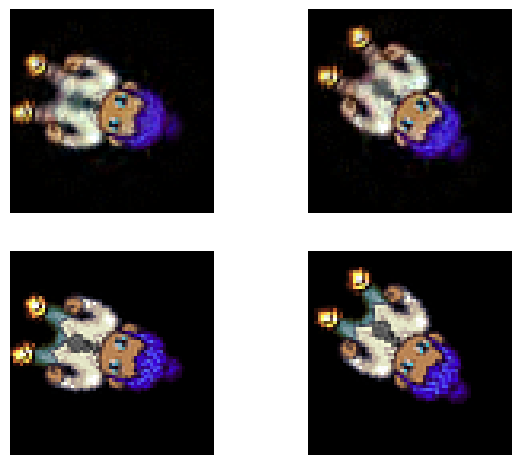

In [137]:
ind = np.random.randint(0, A_test_img.shape[0])

plt.subplot(2, 2, 3)
plt.imshow(A_test_img[ind])
# plt.title("view A")
plt.axis("off")

plt.subplot(2, 2, 1)
plt.imshow(a_hat_img[ind])
# plt.title("view A reconstruction")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(B_test_img[ind], cmap="gray")
# plt.title("view B")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(b_hat_img[ind], cmap="gray")
# plt.title("view B reconstruction")

plt.tight_layout()
plt.axis("off")
# plt.imshow(recon_rot[0])
plt.savefig("../../figures/dmvae_sprite_recon1.svg", transparent=True, dpi=300)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


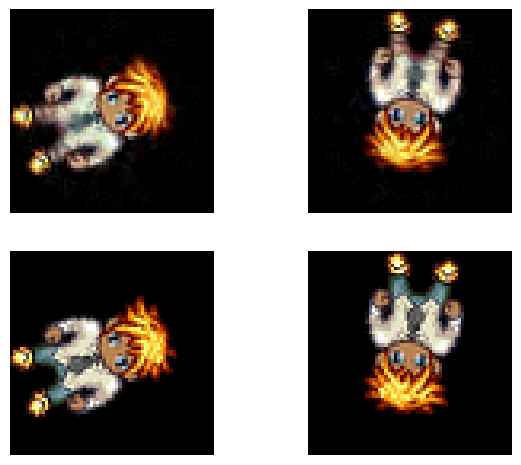

In [138]:
ind = np.random.randint(0, A_test_img.shape[0])

plt.subplot(2, 2, 3)
plt.imshow(A_test_img[ind])
# plt.title("view A")
plt.axis("off")

plt.subplot(2, 2, 1)
plt.imshow(a_hat_img[ind])
# plt.title("view A reconstruction")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(B_test_img[ind], cmap="gray")
# plt.title("view B")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(b_hat_img[ind], cmap="gray")
# plt.title("view B reconstruction")

plt.tight_layout()
plt.axis("off")
# plt.imshow(recon_rot[0])
plt.savefig("../../figures/dmvae_sprite_recon1.svg", transparent=True, dpi=300)